In [1]:
import os
print(os.getcwd())  

...\projet_nlp\notebooks


In [2]:
import pandas as pd

GROUPES = ["cs", "math", "physics", "q-bio", "q-fin", "stat", "eess", "econ"]

# ".." = on remonte d'un dossier, car le notebook est dans notebooks/
df = pd.read_csv("../data/raw/arxiv_echantillon.csv", dtype={"id": str})

print("Taille :", df.shape)
df.head()

Taille : (17349, 11)


,id,title,abstract,cs,math,physics,q-bio,q-fin,stat,eess,econ
0,0704.0125,Anisotropic thermo-elasticity in 2D -- Part I:...,In this note we develop tools and techniques...,0,1,0,0,0,0,0,0
1,0704.0395,A Study of $B_{d}^0 \to J/\Psi \eta^{(\prime)}...,Motivated by the very recent measurement of ...,0,0,1,0,0,0,0,0
2,0704.0685,A generalization of Chebyshev polynomials and ...,In this paper we give a generalization of Ch...,0,1,0,0,0,0,0,0
3,0704.1169,Holographic bound and protein linguistics,The holographic bound in physics constrains ...,0,0,1,1,0,0,0,0
4,0704.2454,Modeling transcription factor binding events t...,Surviving in a diverse environment requires ...,0,0,0,1,0,0,0,0


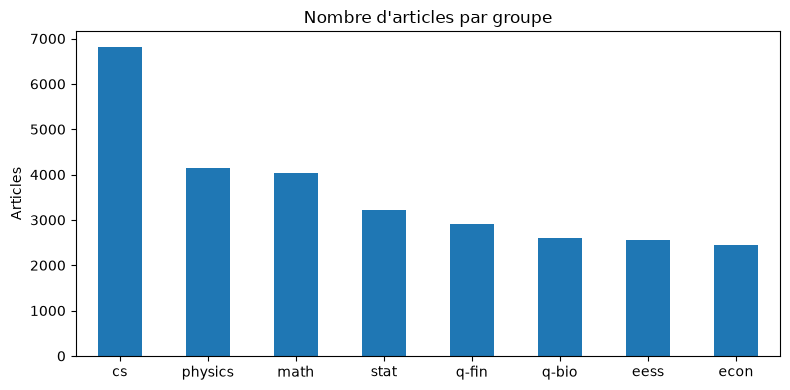

In [3]:
import matplotlib.pyplot as plt

# Somme de chaque colonne = nombre d'articles dans chaque groupe
compte = df[GROUPES].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
compte.plot(kind="bar")
plt.title("Nombre d'articles par groupe")
plt.ylabel("Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../results/repartition_groupes.png", dpi=150)  # image gardée pour le README
plt.show()

1    8320
2    6978
3    1763
4     264
5      23
6       1
Name: count, dtype: int64
Moyenne : 1.66 groupe(s) par article


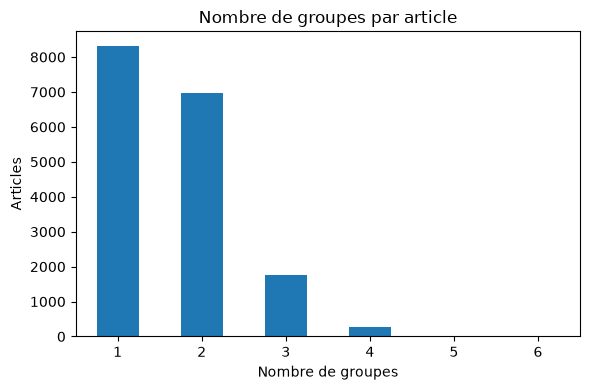

In [4]:
# Pour chaque article (chaque ligne) : combien de 1 sur sa ligne ?
nb_groupes = df[GROUPES].sum(axis=1)

repartition = nb_groupes.value_counts().sort_index()
print(repartition)
print("Moyenne :", round(nb_groupes.mean(), 2), "groupe(s) par article")

plt.figure(figsize=(6, 4))
repartition.plot(kind="bar")
plt.title("Nombre de groupes par article")
plt.xlabel("Nombre de groupes")
plt.ylabel("Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../results/nb_groupes_par_article.png", dpi=150)
plt.show()

           cs  math  physics  q-bio  q-fin  stat  eess  econ
cs       6819  1215      430    704    591  1558  2093   591
math     1215  4040      502    272    496   834   379   242
physics   430   502     4154    885    402   181   133   144
q-bio     704   272      885   2592     16   209   107    23
q-fin     591   496      402     16   2910   281    31  1140
stat     1558   834      181    209    281  3229   103   494
eess     2093   379      133    107     31   103  2558    40
econ      591   242      144     23   1140   494    40  2440


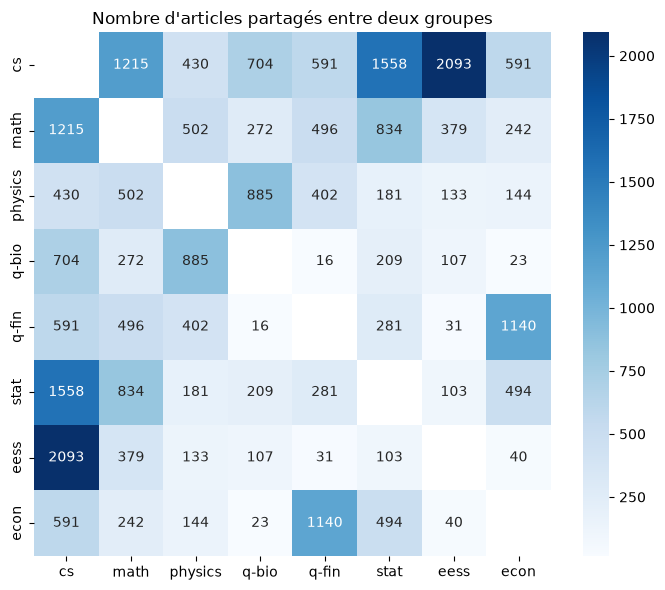

In [5]:
import numpy as np
import seaborn as sns

# Tableau 8 x 8 rempli de 0
cooc = pd.DataFrame(0, index=GROUPES, columns=GROUPES)

# Pour chaque paire (a, b) : nombre d'articles qui ont a = 1 ET b = 1
for a in GROUPES:
    for b in GROUPES:
        cooc.loc[a, b] = ((df[a] == 1) & (df[b] == 1)).sum()

print(cooc)

# On cache la diagonale (cs avec cs = taille du groupe, déjà vue dans le 1er graphique)
masque = np.eye(len(GROUPES), dtype=bool)

plt.figure(figsize=(7, 6))
sns.heatmap(cooc, mask=masque, annot=True, fmt="d", cmap="Blues")
plt.title("Nombre d'articles partagés entre deux groupes")
plt.tight_layout()
plt.savefig("../results/cooccurrence_groupes.png", dpi=150)
plt.show()

count    17349.000000
mean       206.864891
std         81.683337
min         35.000000
25%        148.000000
50%        199.000000
75%        258.000000
max        931.000000
Name: nb_tokens, dtype: float64

Résumés de plus de 256 tokens : 25.4 %
Résumés de plus de 320 tokens : 9.0 %
Résumés de plus de 384 tokens : 2.1 %
Résumés de plus de 512 tokens : 0.2 %


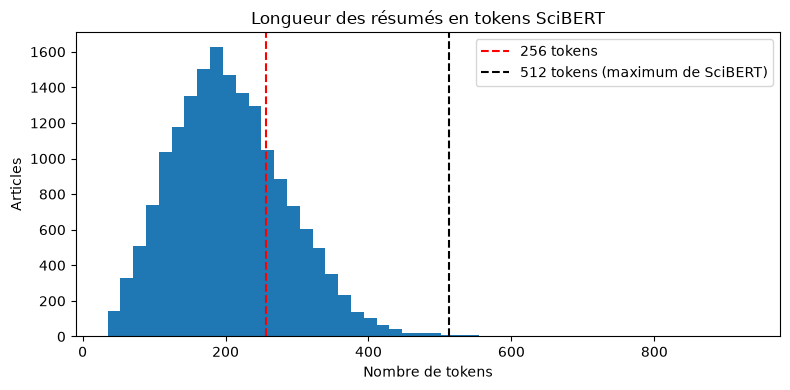

In [7]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("allenai/scibert_scivocab_uncased")

# On tokenise tous les résumés d'un coup ; input_ids = la liste des tokens de chaque résumé
encodages = tokenizer(df["abstract"].tolist())
df["nb_tokens"] = [len(ids) for ids in encodages["input_ids"]]

print(df["nb_tokens"].describe())
print()
for limite in [256, 320, 384, 512]:
    pct = 100 * (df["nb_tokens"] > limite).mean()
    print(f"Résumés de plus de {limite} tokens : {pct:.1f} %")

plt.figure(figsize=(8, 4))
plt.hist(df["nb_tokens"], bins=50)
plt.axvline(256, color="red", linestyle="--", label="256 tokens")
plt.axvline(512, color="black", linestyle="--", label="512 tokens (maximum de SciBERT)")
plt.title("Longueur des résumés en tokens SciBERT")
plt.xlabel("Nombre de tokens")
plt.ylabel("Articles")
plt.legend()
plt.tight_layout()
plt.savefig("../results/longueur_resumes.png", dpi=150)
plt.show()

## Conclusions de l'exploration

- **Données** : 17 349 résumés arXiv, 8 groupes, échantillonnage rééquilibré (~2 500 articles visés par groupe).
- **Répartition** : cs est le plus grand groupe (6 819), econ le plus petit (2 440). Déséquilibre modéré (×2,8).
- **Multi-label** : 48 % des articles ont 1 groupe, 40 % en ont 2. Moyenne : 1,66 groupe par article.
- **Co-occurrences** : cs+eess (82 % des articles eess sont aussi en cs), cs+stat, q-fin+econ.
  Hypothèse : eess sera le groupe le plus difficile à prédire.
- **Longueur** : médiane de 199 tokens SciBERT. Choix de `max_length = 384` (97,9 % des résumés entiers).